# Exploratory data analysis

29 weekly price series (11 products, 6 countries), January 2015 to October 2026, prices in €/kg at the packing station.
After every part there is a short note on what the result means for the forecasting.

## 1. Consistency checks

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "results" / "figures"
TAB = ROOT / "results" / "tables"

df = pd.read_parquet(ROOT / "data" / "processed" / "prices_weekly.parquet")
sample = pd.read_csv(TAB / "sample_series.csv")
df = df[df["series_id"].isin(sample["series_id"])].copy()
df["name"] = df["country"] + " " + df["product"]
df["month"] = df["date"].dt.month
df["year"] = df["date"].dt.year
print(df["name"].nunique(), "series,", len(df), "rows")

29 series, 17864 rows


In [3]:
print("weeks per series:", df.groupby("name").size().unique())
print("duplicate weeks:", df.duplicated(["name", "date"]).sum())
print("all mondays:", (df["date"].dt.day_of_week == 0).all())
print("one product per series:", (df.groupby("name")["product"].nunique() == 1).all())
print("price range €/kg:", round(df["price"].min(), 3), "to", round(df["price"].max(), 2))

weeks per series: [616]
duplicate weeks: 0
all mondays: True
one product per series: True
price range €/kg: 0.035 to 17.22


**Notes:**

- All the 29 series have 616 weeks, no duplicate weeks, the dates are mondays and every series is one product. Prices are in euro/kg and range from €0.035/kg to €17.22/kg.

## 2. Descriptive statistics
CV = std / mean, so cheap and expensive products can be compared.

In [4]:
real = df[~df["is_missing"]]
stats = real.groupby("name")["price"].agg(["mean", "median", "min", "max", "std"]).round(2)
stats["cv"] = (stats["std"] / stats["mean"]).round(2)
stats = stats.sort_values("cv")
stats.to_csv(TAB / "eda_descriptive.csv")
stats

,mean,median,min,max,std,cv
name,,,,,,
IT Apples,0.82,0.81,0.35,1.18,0.14,0.17
IT Lemons,1.18,1.15,0.70,2.00,0.25,0.21
FR Apples,1.08,1.14,0.65,1.63,0.24,0.22
ES Apples,0.81,0.80,0.44,1.43,0.22,0.27
ES Lemons,1.16,1.11,0.57,2.40,0.32,0.28
ES Pears,1.00,0.92,0.61,2.07,0.29,0.29
ES Peppers,1.13,1.06,0.51,2.43,0.35,0.31
IT Lettuces,1.01,1.05,0.26,1.75,0.31,0.31
ES Lettuces,0.96,0.90,0.40,2.64,0.31,0.32


**Notes:**

- Apples are the calmest because they can be stored for a long time. Spanish vegetables are the most volatile with a high CV because they spoil faster. Strawberries are the most expensive. So for the models volatile products will have more errors.

## 3. Prices over time

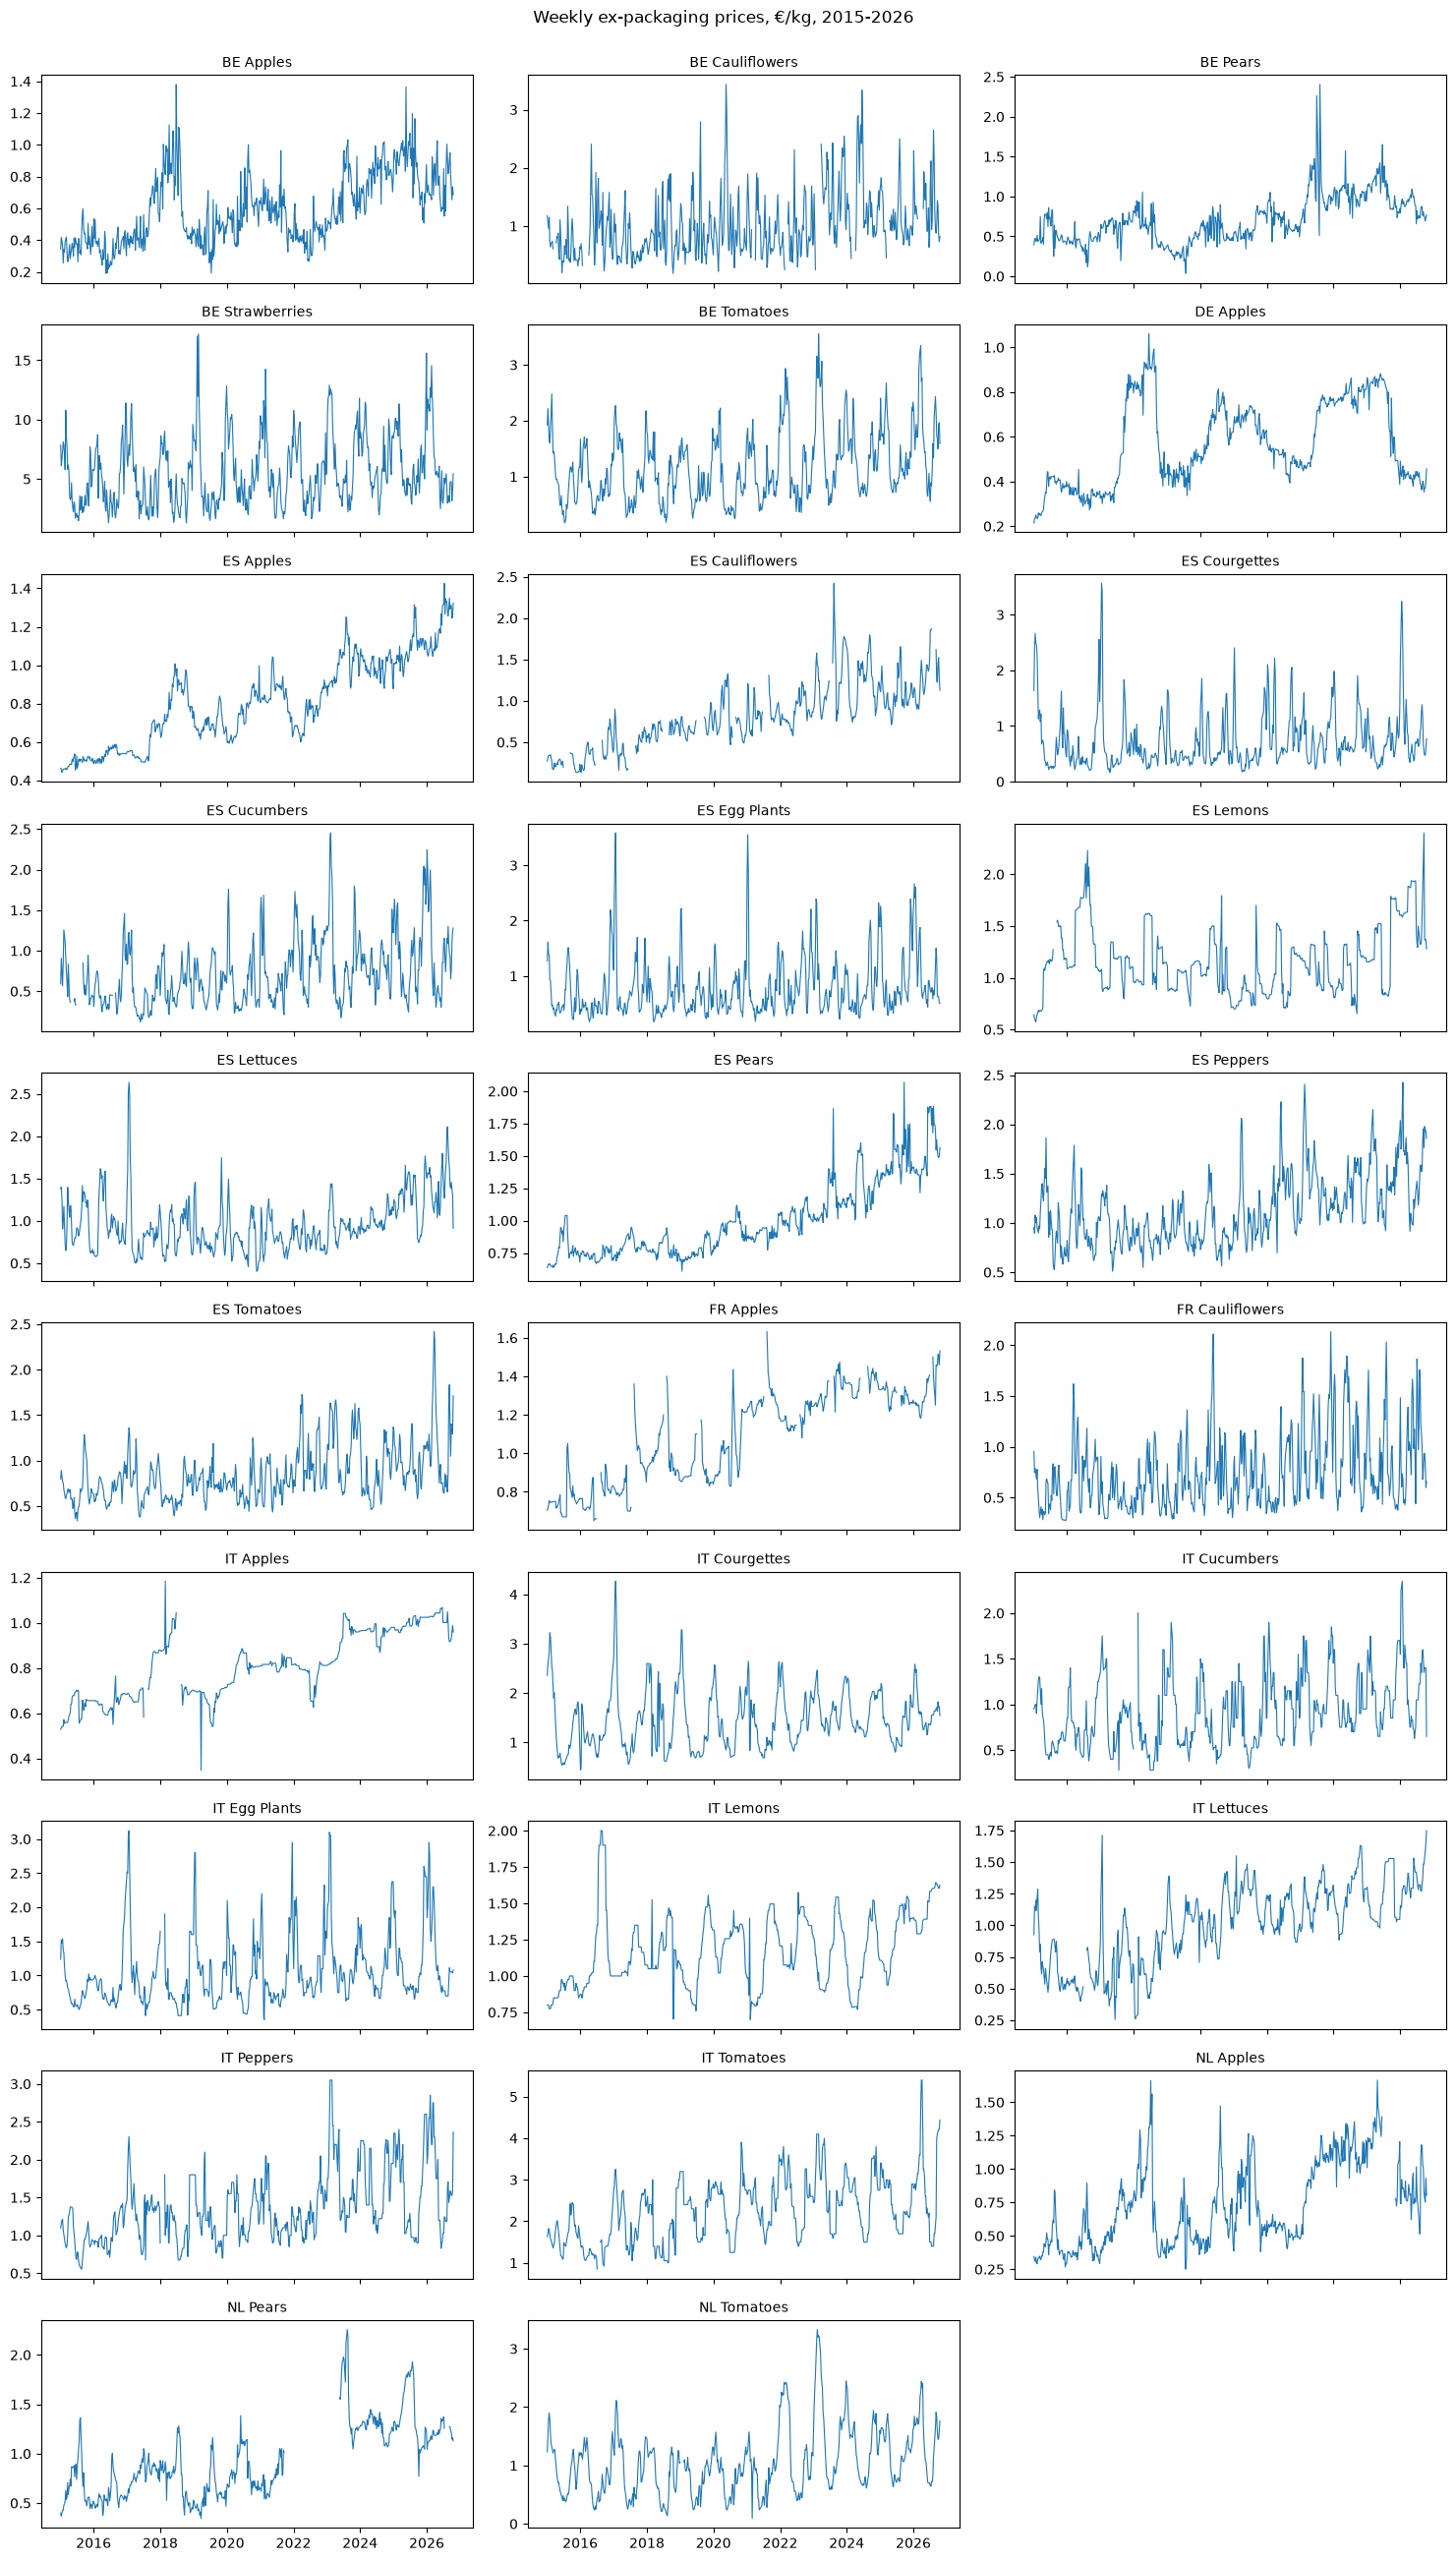

In [5]:
names = sorted(df["name"].unique())
fig, axes = plt.subplots(10, 3, figsize=(15, 26), sharex=True)
for ax, name in zip(axes.flat, names):
    s = df[df["name"] == name]
    ax.plot(s["date"], s["price"], lw=0.8)
    ax.set_title(name, fontsize=10)
for ax in axes.flat[len(names):]:
    ax.axis("off")
fig.suptitle("Weekly ex-packaging prices, €/kg, 2015-2026", y=1.0)
fig.tight_layout()
fig.savefig(FIG / "eda_all_series.png", dpi=110)

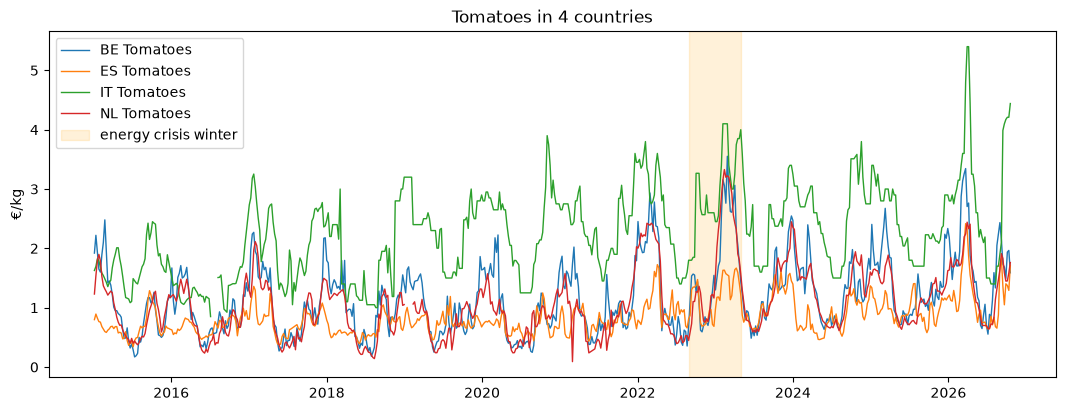

In [6]:
tom = df[df["product"] == "Tomatoes"]
fig, ax = plt.subplots(figsize=(13, 4.5))
for name, s in tom.groupby("name"):
    ax.plot(s["date"], s["price"], lw=1, label=name)
ax.axvspan(pd.Timestamp("2022-09-01"), pd.Timestamp("2023-04-30"), color="orange", alpha=0.15, label="energy crisis winter")
ax.set_ylabel("€/kg"); ax.legend(); ax.set_title("Tomatoes in 4 countries")
fig.savefig(FIG / "eda_tomatoes.png", dpi=110, bbox_inches="tight")

**Notes:**

- Belgian & Dutch tomatoes rose during the energy crisis winter. A model trained on normal years will probably make errors in this period.

## 4. Missing values

name
NL Pears           100.0
NL Apples           46.0
ES Cucumbers        33.0
ES Cauliflowers     25.0
FR Apples           23.0
dtype: float64


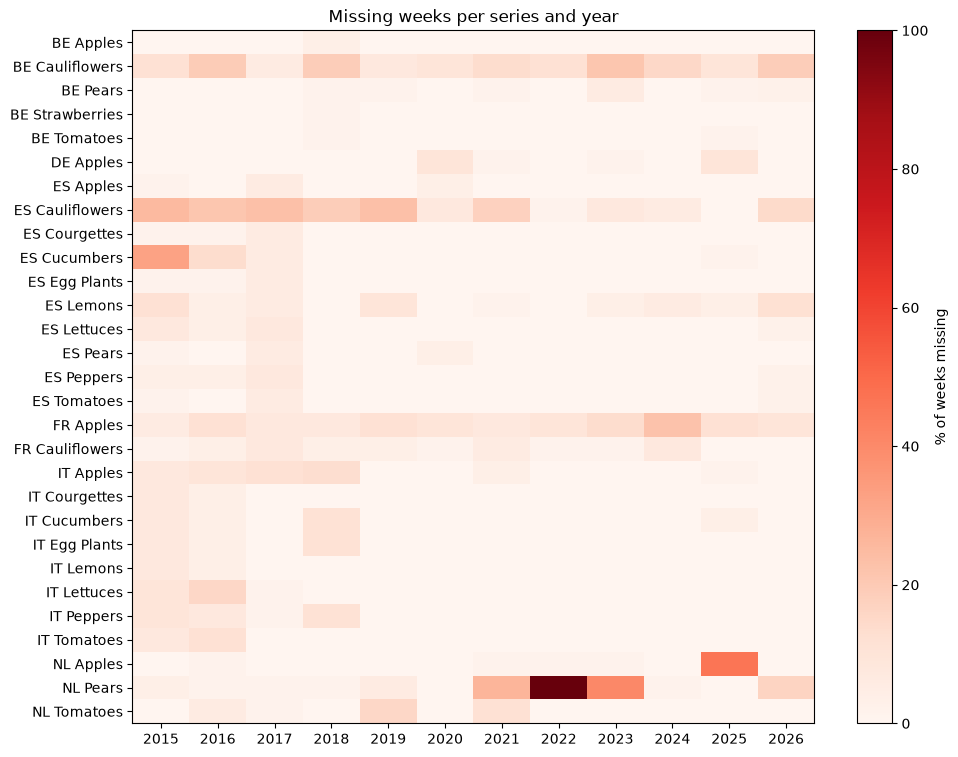

In [7]:
miss = df.pivot_table(index="name", columns="year", values="is_missing", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(miss, cmap="Reds", vmin=0, vmax=100, aspect="auto")
ax.set_yticks(range(len(miss.index)), miss.index)
ax.set_xticks(range(len(miss.columns)), miss.columns)
fig.colorbar(im, label="% of weeks missing")
ax.set_title("Missing weeks per series and year")
fig.savefig(FIG / "eda_missing.png", dpi=110, bbox_inches="tight")
print(miss.max(axis=1).sort_values(ascending=False).head(5).round(0))

In [8]:
gaps = df.groupby("name").agg(missing=("is_missing", "sum"), filled=("is_filled", "sum"), longest_gap=("gap_len", "max"))
gaps["still_empty"] = gaps["missing"] - gaps["filled"]
gaps.sort_values("missing", ascending=False).head(8)

,missing,filled,longest_gap,still_empty
name,,,,
NL Pears,103,10,86,93
ES Cauliflowers,85,9,12,76
BE Cauliflowers,83,35,9,48
FR Apples,66,9,11,57
ES Lemons,29,24,5,5
ES Cucumbers,28,9,10,19
NL Apples,28,8,20,20
IT Apples,25,12,7,13


**Notes:**

- Dutch pears have a big gap of 86 weeks, and cauliflowers have gaps every year. I only filled gaps of up to 3 weeks. Longer gaps stay empty, because filling them would mean inventing too many prices.

## 5. Seasonality
Price divided by the series average, so 1 = normal price.

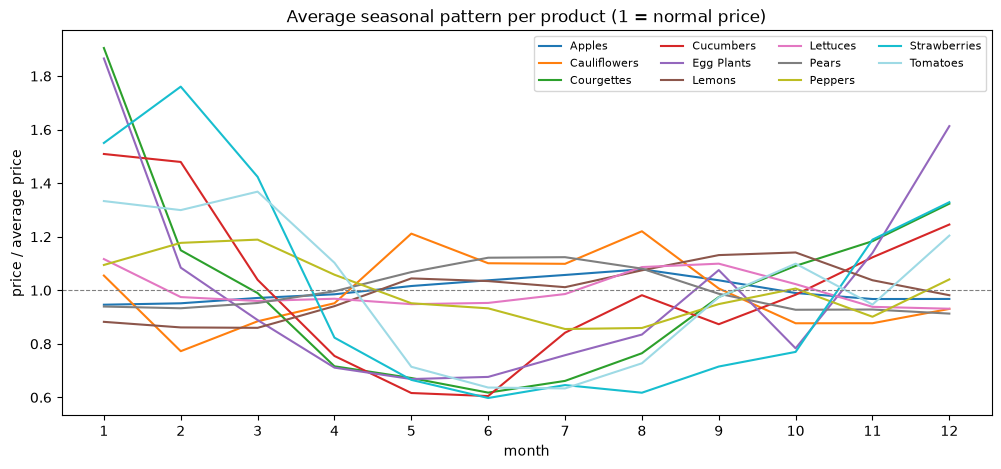

In [9]:
df["rel"] = df["price"] / df.groupby("name")["price"].transform("mean")
profile = df.groupby(["product", "month"])["rel"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(12, 5))
colors = plt.cm.tab20(np.linspace(0, 1, profile.shape[1]))
profile.plot(ax=ax, lw=1.5, color=colors)
ax.axhline(1, color="grey", lw=0.8, ls="--")
ax.set_xticks(range(1, 13)); ax.set_xlabel("month"); ax.set_ylabel("price / average price")
ax.set_title("Average seasonal pattern per product (1 = normal price)")
ax.legend(ncol=4, fontsize=8)
fig.savefig(FIG / "eda_seasonality.png", dpi=110, bbox_inches="tight")

In [10]:
df["log_p"] = np.log(df["price"])
df["detrended"] = df["log_p"] - df.groupby(["name", "year"])["log_p"].transform("mean")
def season_strength(g):
    g = g.dropna(subset=["detrended"])
    monthly = g.groupby("month")["detrended"].transform("mean")
    return 1 - (g["detrended"] - monthly).var() / g["detrended"].var()
strength = df.groupby("name").apply(season_strength).round(2).sort_values()
strength

/var/folders/n8/1rvfdtcx18v_h3gnv2_pdkgw0000gn/T/ipykernel_92500/3060231105.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  strength = df.groupby("name").apply(season_strength).round(2).sort_values()


name
BE Pears           0.04
ES Lettuces        0.06
DE Apples          0.06
BE Apples          0.07
IT Apples          0.08
BE Cauliflowers    0.10
ES Cauliflowers    0.12
ES Peppers         0.15
FR Cauliflowers    0.17
IT Lettuces        0.18
NL Apples          0.25
ES Lemons          0.26
FR Apples          0.28
ES Pears           0.29
ES Tomatoes        0.32
ES Apples          0.35
IT Peppers         0.36
ES Courgettes      0.42
ES Egg Plants      0.48
NL Pears           0.48
ES Cucumbers       0.50
IT Cucumbers       0.51
IT Tomatoes        0.58
IT Lemons          0.59
IT Courgettes      0.60
BE Strawberries    0.63
IT Egg Plants      0.67
BE Tomatoes        0.70
NL Tomatoes        0.73
dtype: float64

**Notes:**

- Strawberries, cucumbers, tomatoes, courgettes, eggplants are very seasonal: expensive in winter and cheap in summer, with a season strength of up to 0.73. Apples and pears have almost no season (0.04), because they are stored for a long time and sold all over the year.

## 6. Outliers: error or real event?

In [11]:
out = df[df["is_outlier"]].sort_values(["name", "date"])
out["run"] = (out.groupby("name")["date"].diff() != pd.Timedelta(weeks=1)).cumsum()
runs = out.groupby("run").agg(name=("name", "first"), start=("date", "min"), weeks=("date", "size"),
                              low=("price", "min"), high=("price", "max"))
runs["type"] = np.where(runs["weeks"] == 1, "single week (check)", "several weeks (likely real event)")
print(len(out), "flagged weeks in", len(runs), "episodes")
print(runs["type"].value_counts())
print(runs[runs["weeks"] > 1].to_string(index=False))

56 flagged weeks in 37 episodes
type
single week (check)                  25
several weeks (likely real event)    12
Name: count, dtype: int64
         name      start  weeks    low   high                              type
  BE Tomatoes 2015-07-13      2 0.1700 0.1900 several weeks (likely real event)
ES Courgettes 2017-01-09      3 2.8470 3.5630 several weeks (likely real event)
ES Courgettes 2021-01-04      3 1.6205 2.4047 several weeks (likely real event)
ES Courgettes 2022-03-28      2 1.9591 2.2162 several weeks (likely real event)
ES Courgettes 2026-01-12      3 2.7134 3.2399 several weeks (likely real event)
ES Egg Plants 2015-08-17      2 1.4766 1.5136 several weeks (likely real event)
ES Egg Plants 2017-01-09      4 2.1263 3.5862 several weeks (likely real event)
ES Egg Plants 2019-01-07      2 2.1916 2.2200 several weeks (likely real event)
ES Egg Plants 2020-01-13      2 1.5406 1.5808 several weeks (likely real event)
ES Egg Plants 2021-01-04      3 2.8285 3.5534 several wee

/var/folders/n8/1rvfdtcx18v_h3gnv2_pdkgw0000gn/T/ipykernel_92500/3618223490.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  out["run"] = (out.groupby("name")["date"].diff() != pd.Timedelta(weeks=1)).cumsum()


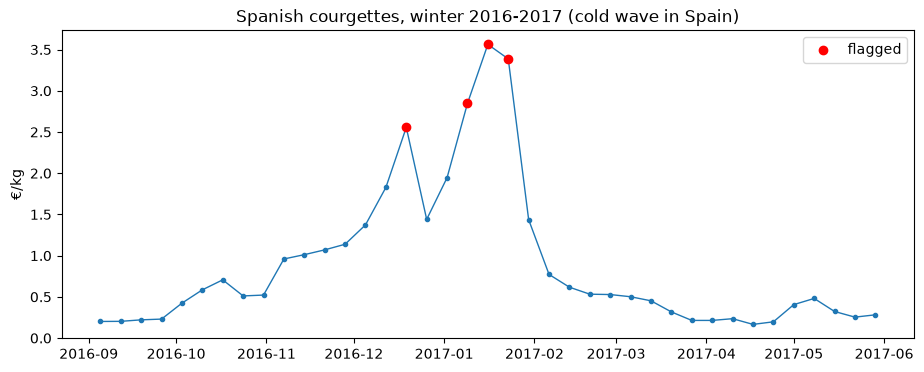

In [12]:
s = df[(df["name"] == "ES Courgettes") & (df["date"].between("2016-09-01", "2017-06-01"))]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(s["date"], s["price"], marker=".", lw=1)
f = s[s["is_outlier"]]
ax.scatter(f["date"], f["price"], color="red", zorder=3, label="flagged")
ax.set_ylabel("€/kg"); ax.legend(); ax.set_title("Spanish courgettes, winter 2016-2017 (cold wave in Spain)")
fig.savefig(FIG / "eda_courgettes_2017.png", dpi=110, bbox_inches="tight")

**Notes:**

- Most multi-week outliers are real events. In January 2017 a cold wave hit south-east Spain and courgette, aubergine and lettuce prices jumped. In January 2021 storm Filomena brought snow to Spain. I keep these values because they are real. Single odd weeks, like Belgian pears at €0.035/kg, are probably reporting errors; they stay flagged. This also shows that weather really moves these prices, which is why I test weather in RQ2.

## 7. Which series should be easy or hard to forecast?

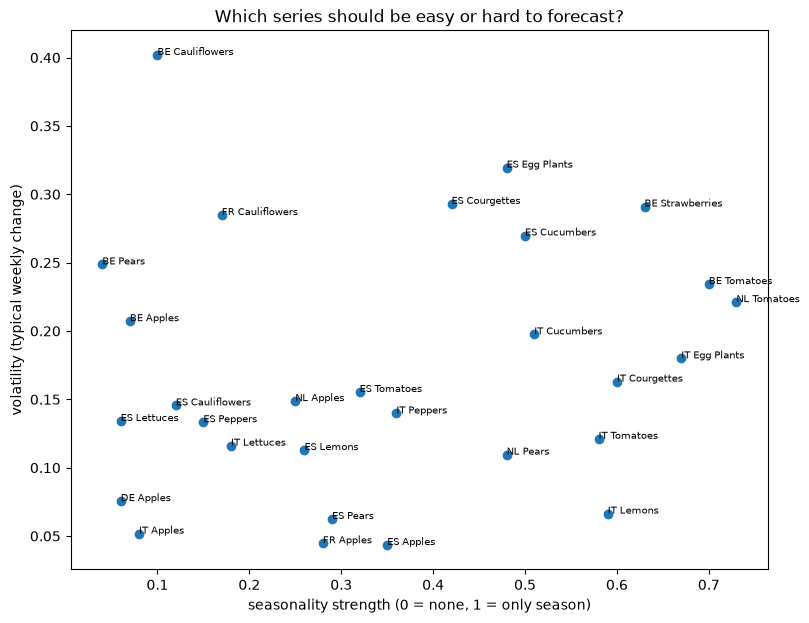

In [13]:
vol = df.sort_values("date").groupby("name")["log_p"].apply(lambda x: x.diff().std())
both = pd.DataFrame({"seasonality": strength, "volatility": vol})
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(both["seasonality"], both["volatility"])
for name, r in both.iterrows():
    ax.annotate(name, (r["seasonality"], r["volatility"]), fontsize=7)
ax.set_xlabel("seasonality strength (0 = none, 1 = only season)")
ax.set_ylabel("volatility (typical weekly change)")
ax.set_title("Which series should be easy or hard to forecast?")
fig.savefig(FIG / "eda_season_vs_volatility.png", dpi=110, bbox_inches="tight")
both.round(3).to_csv(TAB / "eda_season_volatility.csv")

**Notes:** my prediction before running any model (3 easiest and 3 hardest series)

- Easiest are italian, spanish and french apples. Hardest are belgian cauliflowers and pears and spanish aubergines.